In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
train_df = pd.read_csv("../data/UNSW_NB15_training-set.csv")
test_df = pd.read_csv("../data/UNSW_NB15_testing-set.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


In [5]:
train_df.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [6]:
train_df.columns.tolist()

['id',
 'dur',
 'proto',
 'service',
 'state',
 'spkts',
 'dpkts',
 'sbytes',
 'dbytes',
 'rate',
 'sttl',
 'dttl',
 'sload',
 'dload',
 'sloss',
 'dloss',
 'sinpkt',
 'dinpkt',
 'sjit',
 'djit',
 'swin',
 'stcpb',
 'dtcpb',
 'dwin',
 'tcprtt',
 'synack',
 'ackdat',
 'smean',
 'dmean',
 'trans_depth',
 'response_body_len',
 'ct_srv_src',
 'ct_state_ttl',
 'ct_dst_ltm',
 'ct_src_dport_ltm',
 'ct_dst_sport_ltm',
 'ct_dst_src_ltm',
 'is_ftp_login',
 'ct_ftp_cmd',
 'ct_flw_http_mthd',
 'ct_src_ltm',
 'ct_srv_dst',
 'is_sm_ips_ports',
 'attack_cat',
 'label']

In [7]:
train_df.dtypes

id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

In [8]:
train_df[["attack_cat", "label"]].head(20)

,attack_cat,label
0,Normal,0
1,Normal,0
2,Normal,0
3,Normal,0
4,Normal,0
5,Normal,0
6,Normal,0
7,Normal,0
8,Normal,0
9,Normal,0


In [9]:
train_df["label"].value_counts()

label
1    119341
0     56000
Name: count, dtype: int64

In [10]:
train_df["label"].value_counts(normalize=True) * 100

label
1    68.062233
0    31.937767
Name: proportion, dtype: float64

In [11]:
train_df["attack_cat"].value_counts()

attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

In [12]:
train_df.isnull().sum()

id                   0
dur                  0
proto                0
service              0
state                0
spkts                0
dpkts                0
sbytes               0
dbytes               0
rate                 0
sttl                 0
dttl                 0
sload                0
dload                0
sloss                0
dloss                0
sinpkt               0
dinpkt               0
sjit                 0
djit                 0
swin                 0
stcpb                0
dtcpb                0
dwin                 0
tcprtt               0
synack               0
ackdat               0
smean                0
dmean                0
trans_depth          0
response_body_len    0
ct_srv_src           0
ct_state_ttl         0
ct_dst_ltm           0
ct_src_dport_ltm     0
ct_dst_sport_ltm     0
ct_dst_src_ltm       0
is_ftp_login         0
ct_ftp_cmd           0
ct_flw_http_mthd     0
ct_src_ltm           0
ct_srv_dst           0
is_sm_ips_ports      0
attack_cat 

In [13]:
missing_values = train_df.isnull().sum()

missing_values[missing_values > 0]

Series([], dtype: int64)

In [14]:
print("Duplicated rows:", train_df.duplicated().sum())

Duplicated rows: 0


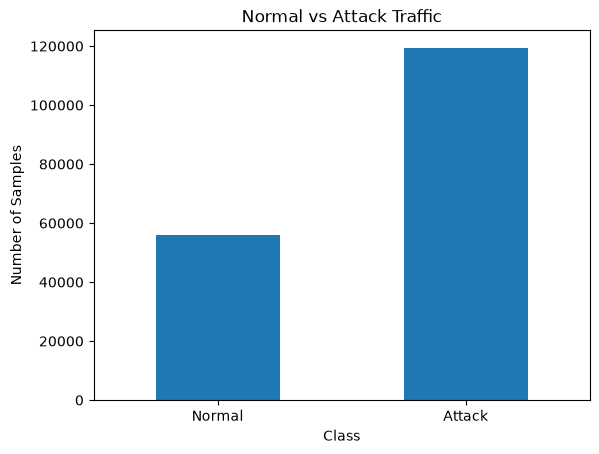

In [18]:
label_counts = train_df["label"].value_counts().sort_index()

label_counts.plot(kind="bar")

plt.title("Normal vs Attack Traffic")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Normal", "Attack"], rotation=0)

plt.show()

In [17]:
features_df = pd.read_csv(
    "../data/NUSW-NB15_features.csv",
    encoding="cp1252"
)

features_df.head(10)

,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [19]:
features_df.columns.tolist()

['No.', 'Name', 'Type ', 'Description']

In [20]:
pd.set_option("display.max_colwidth", None)
features_df.head(45)

,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,"Indicates to the state and its dependent protocol, e.g. ACC, CLO, CON, ECO, ECR, FIN, INT, MAS, PAR, REQ, RST, TST, TXD, URH, URN, and (-) (if not used state)"
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [21]:
train_df.select_dtypes(include="object").columns.tolist()

/var/folders/dp/ghlsz16s7djdxgysm13gn2dm0000gn/T/ipykernel_32708/3748632389.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_df.select_dtypes(include="object").columns.tolist()


['proto', 'service', 'state', 'attack_cat']

In [22]:
X_train = train_df.drop(columns=["id", "label", "attack_cat"])
y_train = train_df["label"]

X_test = test_df.drop(columns=["id", "label", "attack_cat"])
y_test = test_df["label"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (175341, 42)
y_train: (175341,)
X_test: (82332, 42)
y_test: (82332,)


In [23]:
categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numeric_features = X_train.select_dtypes(
    exclude=["object", "str"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))
print("Number of numeric features:", len(numeric_features))

Categorical features: ['proto', 'service', 'state']
Number of categorical features: 3
Number of numeric features: 39


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Model pipeline created successfully!")

Model pipeline created successfully!


In [27]:
import time

start_time = time.time()

model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Model training completed!")
print(f"Training time: {training_time:.2f} seconds")

Model training completed!
Training time: 19.79 seconds


In [28]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 82332


In [29]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

Accuracy: 0.8711
Accuracy percentage: 87.11%


In [30]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Attack"]
    )
)

              precision    recall  f1-score   support

      Normal       0.98      0.73      0.84     37000
      Attack       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.86     82332
weighted avg       0.89      0.87      0.87     82332



In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[27030  9970]
 [  640 44692]]


In [32]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives  - Normal correctly detected:", tn)
print("False Positives - Normal incorrectly flagged as Attack:", fp)
print("False Negatives - Attacks missed:", fn)
print("True Positives  - Attacks correctly detected:", tp)

True Negatives  - Normal correctly detected: 27030
False Positives - Normal incorrectly flagged as Attack: 9970
False Negatives - Attacks missed: 640
True Positives  - Attacks correctly detected: 44692


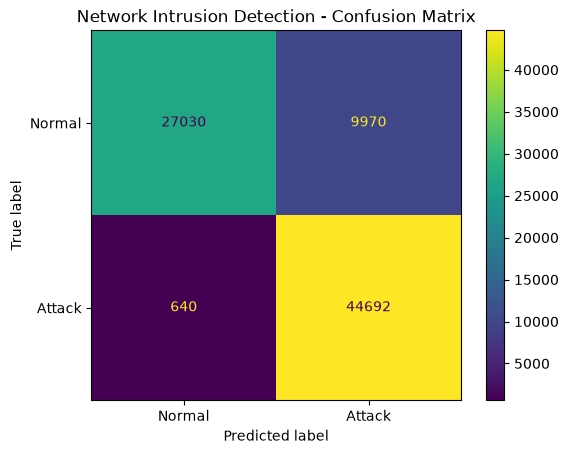

In [33]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Attack"]
)

plt.title("Network Intrusion Detection - Confusion Matrix")
plt.show()

In [34]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)

Training: (140272, 42)
Validation: (35069, 42)


In [35]:
model.fit(X_train_final, y_train_final)

print("Training completed!")

Training completed!


In [36]:
y_val_pred = model.predict(X_val)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Normal", "Attack"]
))

print(confusion_matrix(y_val, y_val_pred))

              precision    recall  f1-score   support

      Normal       0.95      0.92      0.94     11200
      Attack       0.96      0.98      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.96      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069

[[10329   871]
 [  557 23312]]


In [37]:
attack_probabilities = model.predict_proba(X_val)[:, 1]

attack_probabilities[:10]

array([0.99, 1.  , 1.  , 1.  , 1.  , 1.  , 0.72, 1.  , 1.  , 0.96])

In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

thresholds = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]

for threshold in thresholds:
    y_threshold_pred = (attack_probabilities >= threshold).astype(int)

    precision = precision_score(y_val, y_threshold_pred)
    recall = recall_score(y_val, y_threshold_pred)
    f1 = f1_score(y_val, y_threshold_pred)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_threshold_pred
    ).ravel()

    print(f"Threshold: {threshold:.2f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"False Positives: {fp}")
    print(f"False Negatives: {fn}")
    print("-" * 40)

Threshold: 0.50
Precision: 0.9629
Recall:    0.9780
F1 Score:  0.9704
False Positives: 900
False Negatives: 525
----------------------------------------
Threshold: 0.55
Precision: 0.9694
Recall:    0.9710
F1 Score:  0.9702
False Positives: 732
False Negatives: 692
----------------------------------------
Threshold: 0.60
Precision: 0.9742
Recall:    0.9635
F1 Score:  0.9688
False Positives: 608
False Negatives: 872
----------------------------------------
Threshold: 0.65
Precision: 0.9786
Recall:    0.9553
F1 Score:  0.9668
False Positives: 499
False Negatives: 1066
----------------------------------------
Threshold: 0.70
Precision: 0.9823
Recall:    0.9450
F1 Score:  0.9633
False Positives: 406
False Negatives: 1313
----------------------------------------
Threshold: 0.75
Precision: 0.9859
Recall:    0.9332
F1 Score:  0.9588
False Positives: 318
False Negatives: 1594
----------------------------------------
Threshold: 0.80
Precision: 0.9891
Recall:    0.9189
F1 Score:  0.9527
False Pos

In [39]:
results = []

for threshold in thresholds:
    y_threshold_pred = (attack_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_threshold_pred
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_threshold_pred),
        "Recall": recall_score(y_val, y_threshold_pred),
        "F1": f1_score(y_val, y_threshold_pred),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,0.50,0.962877,0.978005,0.970382,900,525
1,0.55,0.969384,0.971008,0.970195,732,692
2,0.60,0.974243,0.963467,0.968825,608,872
3,0.65,0.978586,0.955340,0.966823,499,1066
4,0.70,0.982319,0.944991,0.963294,406,1313
5,0.75,0.985925,0.933219,0.958848,318,1594
6,0.80,0.989087,0.918933,0.952720,242,1935


In [40]:
def get_severity(risk_score):
    if risk_score < 30:
        return "LOW"
    elif risk_score < 60:
        return "MEDIUM"
    elif risk_score < 80:
        return "HIGH"
    else:
        return "CRITICAL"

In [41]:
for probability in attack_probabilities[:10]:
    risk = probability * 100

    print(
        f"Risk Score: {risk:.0f}/100 | "
        f"Severity: {get_severity(risk)}"
    )

Risk Score: 99/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 72/100 | Severity: HIGH
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 100/100 | Severity: CRITICAL
Risk Score: 96/100 | Severity: CRITICAL


In [42]:
SELECTED_THRESHOLD = 0.55

model.fit(X_train, y_train)

print("Final model trained on the complete training set!")

Final model trained on the complete training set!


In [43]:
test_attack_probabilities = model.predict_proba(X_test)[:, 1]

y_test_pred = (
    test_attack_probabilities >= SELECTED_THRESHOLD
).astype(int)

print("Final test predictions completed!")

Final test predictions completed!


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Normal", "Attack"]
    )
)

cm_final = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm_final)

              precision    recall  f1-score   support

      Normal       0.97      0.76      0.85     37000
      Attack       0.83      0.98      0.90     45332

    accuracy                           0.88     82332
   macro avg       0.90      0.87      0.88     82332
weighted avg       0.89      0.88      0.88     82332

Confusion Matrix:
[[28132  8868]
 [  873 44459]]


In [45]:
tn, fp, fn, tp = cm_final.ravel()

print("\nFINAL TEST RESULTS")
print("--------------------------")
print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

print(f"\nAccuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_test_pred):.4f}")


FINAL TEST RESULTS
--------------------------
True Negatives : 28132
False Positives: 8868
False Negatives: 873
True Positives : 44459

Accuracy : 0.8817
Precision: 0.8337
Recall   : 0.9807
F1 Score : 0.9013


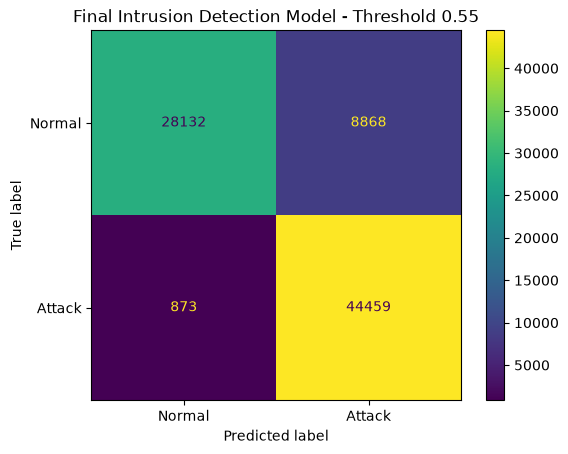

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Normal", "Attack"]
)

plt.title(
    f"Final Intrusion Detection Model - Threshold {SELECTED_THRESHOLD}"
)

plt.show()

In [47]:
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

In [48]:
import joblib

joblib.dump(
    model,
    "../models/intrusion_detection_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [49]:
import json

config = {
    "model": "RandomForestClassifier",
    "threshold": SELECTED_THRESHOLD,
    "target": "binary_intrusion_detection",
    "normal_label": 0,
    "attack_label": 1
}

with open("../models/model_config.json", "w") as file:
    json.dump(config, file, indent=4)

print("Model configuration saved!")

Model configuration saved!
